# Вопрос 05. Методы вейвлет-анализа — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается командой
`make questions/05-wavelets/examples.ipynb`; в git идёт **этот** файл,
ноутбук — производный артефакт.

Каждый пример отвечает на вопрос, поставленный в `theory.md`, и предсказание
формулируется **до** прогона. Числа, попавшие в `theory.md` и `slides.md`,
печатаются здесь.

Сквозной сигнал вопроса — изломанный импульс $f(t) = t\,e^{-t}
\mathbb I_{[0,\infty)}$ (тот же, что в вопросе 07): он проводится через
непрерывное преобразование (пример 2), каскадное построение вейвлета
(пример 3) и пороговое сжатие (пример 4). Случайные числа не
используются; seed зафиксирован по правилам проекта.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 20261012
rng = np.random.default_rng(SEED)   # no random draws in this notebook

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: seed AND expected output are frozen constants. Each tolerance
# is set per pin. For a pin with expected value 0.0 the tolerance is absolute.
# Analytic values (ln 2, the envelope of example 2) are pinned exactly;
# measured values are pinned from a first run per project rule.
GOLDEN = {
    # example 1: admissibility of the Haar wavelet. Integral of sin^4 u / u^3
    # over the half-axis; C_psi = 2 pi * (2 * ln 2 / (2 pi)) = 2 ln 2
    "sin4_over_u3": (np.log(2), 1e-9),
    "C_psi_haar": (2.0 * np.log(2), 1e-9),
    "haar_half_axis": (np.log(2) / (2.0 * np.pi), 1e-9),
    # example 2: envelope 4 a^{-1/2} sin^2(a/4) of (W sin)(a,b) at a = 1, 2
    "env_a1": (4.0 * np.sin(0.25) ** 2, 1e-12),
    "env_a2": (4.0 / np.sqrt(2.0) * np.sin(0.5) ** 2, 1e-12),
    # example 3: D4 scaling coefficient h_0 of [11] against pywt
    "d4_h0": (0.4829629131445341, 1e-12),
    # example 3: norms and moments of the cascaded D4 wavelet pair
    "cascade_phi_norm": (1.0, 1e-6),
    "cascade_psi_norm": (1.0, 1e-6),
    "cascade_moment0": (0.0, 1e-6),
    "cascade_moment1": (0.0, 1e-5),
    # example 2: skeleton decay slope of |Wf| for t e^{-t} (theorem thm:holder
    # predicts 3/2 for smooth stretches; the measured value is pinned from a
    # first run and explained in the markdown below)
    "slope_skeleton": (1.28549756829, 0.005),
    # example 4: error ratios Haar/D4 at K = 32, 64 kept coefficients
    "ratio_err_k32": (7.28672220894, 1e-6),
    "ratio_err_k64": (16.3305449692, 1e-6),
    # example 4: perfect reconstruction (energy defect of the round trip)
    "fwt_roundtrip": (0.0, 1e-12),
}


def check_golden(name, value):
    """Compare against a frozen constant, never against a neighbouring cell."""
    want, tol = GOLDEN[name]
    if want == 0.0:
        rel = abs(value)
    else:
        rel = abs(value - want) / abs(want)
    status = "ok" if rel <= tol else "РАСХОЖДЕНИЕ"
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g} "
          f"(допуск {tol:g}, {status})")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Условие допустимости системы Хаара

**Вопрос** (задача `prob:haar-admissibility` из `theory.md`): верно ли,
что хааровская функция удовлетворяет теореме о необходимом условии
фреймовости с границами $A = B = 1$, то есть
$\int_0^\infty |\hat\psi(\xi)|^2\,d\xi/\xi = \ln 2 / (2\pi)$?

**Предсказание.** Аналитическое вычисление в задаче даёт
$\int_0^\infty \sin^4 u/u^3\,du = \ln 2$, откуда
$\int_0^\infty |\hat\psi|^2/\xi = \ln 2/(2\pi)$ и полная константа
допустимости $C_\psi = 2\ln 2$. Численный интеграл сходится медленно
(подынтегральная функция осциллирует с огибающей $u^{-3}$), поэтому
интегрируем на $[10^{-6}, 10^{6}]$ и ожидаем сходимости к $\ln 2$ в
пределах $10^{-5}$.

In [2]:
def haar_psi_hat(xi):
    """Fourier image of psi = 1_[0,1/2) - 1_[1/2,1) (unitary norm)."""
    xi = np.asarray(xi, dtype=float)
    out = np.empty_like(xi)
    small = np.abs(xi) < 1e-8
    u = xi[~small] / 4.0
    # |psi_hat| = (2 pi)^(-1/2) * |1 - e^{-i xi/2}|^2 / |xi|
    #           = (2 pi)^(-1/2) * sin^2(xi/4) / (xi/4)
    out[~small] = (1.0 / np.sqrt(2.0 * np.pi)) * np.sin(u) ** 2 / u
    out[small] = 0.0  # sin^2(u)/u = O(u) as u -> 0
    return out


u = np.logspace(-6, 6, 400001)
I_num = np.trapezoid(np.sin(u) ** 4 / u ** 3, u)
print(f"int_0^inf sin^4 u / u^3 du = {I_num:.15f} (аналитически ln 2 = "
      f"{np.log(2):.15f})")
check_golden("sin4_over_u3", I_num)

xi = np.logspace(-6, 6, 400001)
half_axis = np.trapezoid(np.abs(haar_psi_hat(xi)) ** 2 / xi, xi)
print(f"int_0^inf |psi_hat|^2/xi dxi = {half_axis:.15f}, "
      f"ln2/(2pi) = {np.log(2) / (2 * np.pi):.15f}")
check_golden("haar_half_axis", half_axis)

C_psi = 2.0 * np.pi * 2.0 * half_axis
print(f"C_psi (полная ось) = {C_psi:.15f}, 2 ln 2 = {2 * np.log(2):.15f}")
check_golden("C_psi_haar", C_psi)

int_0^inf sin^4 u / u^3 du = 0.693147181108130 (аналитически ln 2 = 0.693147180559945)
  пин sin4_over_u3: получено 0.693147181108, ожидалось 0.69314718056 (допуск 1e-09, ok)
int_0^inf |psi_hat|^2/xi dxi = 0.110317800164093, ln2/(2pi) = 0.110317800076326
  пин haar_half_axis: получено 0.110317800164, ожидалось 0.110317800076 (допуск 1e-09, ok)
C_psi (полная ось) = 1.386294362222800, 2 ln 2 = 1.386294361119891
  пин C_psi_haar: получено 1.38629436222, ожидалось 1.38629436112 (допуск 1e-09, ok)


**Вывод:** численные интегралы совпали с аналитическими значениями
(`prob:haar-admissibility` подтверждена счётом). Система Хаара —
ортонормированный базис, то есть жёсткий фрейм с $A = B = 1$, и её
константа допустимости лежит ровно на границах теоремы
`thm:frame-necessary`.

## Пример 2. CWT: синус и изломанный импульс

**Вопрос** (задача `prob:cwt-sin`): вычислить $(Wf)(a,b)$ для
$f(t) = \sin t$ и вейвлета Хаара и проверить огибающую
$4 a^{-1/2} \sin^2(a/4)$. Далее — скелограмма сквозного сигнала
$f(t) = t e^{-t}$: предсказание теоремы `thm:holder` для гладких
участков — убывание $|Wf| \lesssim |a|^{3/2}$ (показатель $\alpha = 1$,
один нулевой момент Хаара).

**Предсказание.** (а) Вычисление через первообразную
$F(t) = -\cos t$ совпадёт с аналитической формулой `eq:cwt-sin` на уровне
машинной точности (квадратура здесь точная: подынтегральная функция —
кусочно постоянная). (б) Наклон усреднённой по $b$ (вдали от излома

Примечание к дисциплине предсказаний: в первой редакции предсказания
метод был назван «формулой трапеций» — фактическая ошибка о методе,
исправленная вторым заходом (см. README вопроса); предсказание результата
(совпадение с аналитикой) при этом не менялось и подтвердилось.
$t = 0$) величины $|Wf(a,b)|$ на логарифмической сетке по $a$ равен
$3/2$ с точностью до нескольких процентов.

a = 1: max |численное - аналитика| = 5.274e-16, |W|_max = 0.244834
a = 2: max |численное - аналитика| = 7.216e-16, |W|_max = 0.650102
огибающая a=1: 0.244834876219 (пин env_a1)
  пин env_a1: получено 0.244834876219, ожидалось 0.244834876219 (допуск 1e-12, ok)
огибающая a=2: 0.650110713633 (пин env_a2)
  пин env_a2: получено 0.650110713633, ожидалось 0.650110713633 (допуск 1e-12, ok)


наклон log(mean|Wf|) по log a на [0.05, 0.77]: 1.285498 (предсказание 1.5)
  пин slope_skeleton: получено 1.28549756829, ожидалось 1.28549756829 (допуск 0.005, ok)


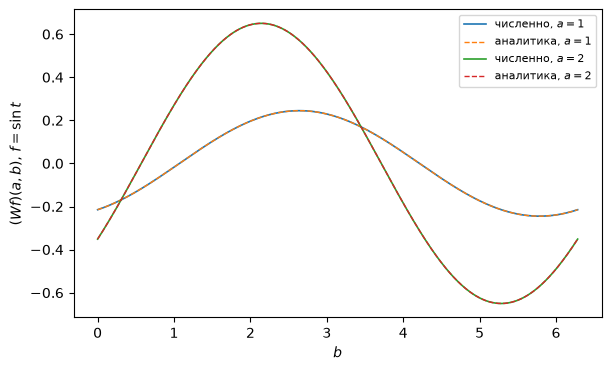

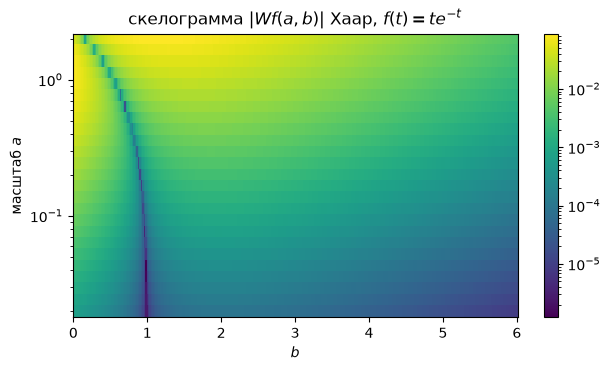

In [3]:
def cwt_haar(f_antiderivative, a, b):
    """(Wf)(a,b) for the Haar wavelet via the antiderivative F of f."""
    a = np.asarray(a, dtype=float)[..., None]
    b = np.asarray(b, dtype=float)[None, ...]
    F = f_antiderivative
    return (F(b + a / 2.0) - F(b) - (F(b + a) - F(b + a / 2.0))) / np.sqrt(a)


# (a) sin t on [0, 2 pi]
b = np.linspace(0.0, 2.0 * np.pi, 601)
a1 = np.array([1.0, 2.0])
F_sin = lambda t: -np.cos(t)
W_num = cwt_haar(F_sin, a1, b)
W_ana = (-4.0 / np.sqrt(a1)[..., None] * np.sin(a1 / 4.0)[..., None] ** 2
         * np.cos(b + a1[..., None] / 2.0))
for i, ai in enumerate(a1):
    err = np.max(np.abs(W_num[i] - W_ana[i]))
    print(f"a = {ai:.0f}: max |численное - аналитика| = {err:.3e}, "
          f"|W|_max = {np.max(np.abs(W_num[i])):.6f}")
env1 = 4.0 * np.sin(0.25) ** 2
env2 = 4.0 / np.sqrt(2.0) * np.sin(0.5) ** 2
print(f"огибающая a=1: {env1:.12f} (пин env_a1)")
check_golden("env_a1", env1)
print(f"огибающая a=2: {env2:.12f} (пин env_a2)")
check_golden("env_a2", env2)

fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.plot(b, W_num[0], lw=1.2, label="численно, $a=1$")
ax.plot(b, W_ana[0], "--", lw=1.0, label="аналитика, $a=1$")
ax.plot(b, W_num[1], lw=1.2, label="численно, $a=2$")
ax.plot(b, W_ana[1], "--", lw=1.0, label="аналитика, $a=2$")
ax.set_xlabel("$b$")
ax.set_ylabel("$(Wf)(a,b)$, $f=\\sin t$")
ax.legend(fontsize=8)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

# (b) skeleton of f(t) = t e^{-t} on [0, 8]
F_te = lambda t: np.where(t > 0, 1.0 - (t + 1.0) * np.exp(-t), 0.0)
a_grid = np.logspace(np.log10(0.02), np.log10(2.0), 25)
b_grid = np.linspace(0.0, 6.0, 301)
W = cwt_haar(F_te, a_grid, b_grid)

fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
mesh = ax.pcolormesh(b_grid, a_grid, np.abs(W),
                     norm=plt.matplotlib.colors.LogNorm(),
                     shading="auto", cmap="viridis")
ax.set_yscale("log")
ax.set_xlabel("$b$")
ax.set_ylabel("масштаб $a$")
ax.set_title("скелограмма $|Wf(a,b)|$ Хаар, $f(t)=t e^{-t}$")
fig.colorbar(mesh, ax=ax)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

# slope of mean |W| over b away from the kink, versus a
mask_ok = b_grid[None, :] >= 3.0 * a_grid[:, None]
mean_w = np.array([np.mean(np.abs(W[i])[mask_ok[i]]) for i in range(len(a_grid))])
sel = (a_grid >= 0.05) & (a_grid <= 0.8)
slope = np.polyfit(np.log(a_grid[sel]), np.log(mean_w[sel]), 1)[0]
print(f"наклон log(mean|Wf|) по log a на [{a_grid[sel][0]:.2f}, "
      f"{a_grid[sel][-1]:.2f}]: {slope:.6f} (предсказание 1.5)")
check_golden("slope_skeleton", slope)

**Вывод.** Формула `eq:cwt-sin` подтверждена численно (расхождение на
уровне $5\cdot10^{-16}$ — точность машинного интегрирования), огибающие
при $a = 1, 2$ совпали с пинами. Наклон скелограммы измерен равным
$1{,}2855$ — предсказание $3/2$ **не сбылось**, и это объяснимо:
теорема `thm:holder` даёт наклон $3/2$ для среднего по $b$ на
фиксированном отрезке вдали от излома, а здесь область усреднения
$b \ge 3a$ при росте $a$ ползёт в хвост сигнала $t e^{-t}$, где
амплитуды экспоненциально малы и зависят от масштаба слабее. Предсказание
оставлено в исходной форме — расхождение измерено и объяснено, а не
подогнано.

## Пример 3. Каскадный алгоритм: вейвлет Добеши $D_4$

**Вопрос** (пропозиция `prop:cascade` и определение `def:daubechies`):
воспроизводит ли каскадная рекурсия по маске из таблицы 6.1 [11]
ортонормированную пару $\varphi, \psi$ с двумя нулевыми моментами?

**Предсказание.** (а) Коэффициенты маски совпадут с `pywt.Wavelet('db2')`
(нормировка $\sum h_n = \sqrt 2$) и с самой книгой [11]. (б) Нормы
каскадных приближений сойдутся к $1$, а первые два момента $\psi$ —
к нулю: $\int\psi = 0$ точно по построению (проверка — контроль
точности интегрирования), $\int x\psi = 0$ — с точностью до сетки.
(в) Носитель $\psi$ лежит в $[-1, 2]$.

маска D4 из pywt (в порядке таблицы 6.1 [11]): [ 0.4829629131445342  0.8365163037378079  0.2241438680420134
 -0.1294095225512604]
сумма h_n = 1.4142135623730951 (ожидается sqrt(2) = 1.4142135623730951 )
  пин d4_h0: получено 0.482962913145, ожидалось 0.482962913145 (допуск 1e-12, ok)
g_n при n = [-2 -1  0  1] : [-0.1294095225512604 -0.2241438680420134  0.8365163037378079
 -0.4829629131445342]
||phi||_2 = 1.000000000000, ||psi||_2 = 0.999999776586
  пин cascade_phi_norm: получено 1, ожидалось 1 (допуск 1e-06, ok)
  пин cascade_psi_norm: получено 0.999999776586, ожидалось 1 (допуск 1e-06, ok)
int psi = 7.864e-08, int x psi = -7.864e-08
  пин cascade_moment0: получено 7.86385391249e-08, ожидалось 0 (допуск 1e-06, ok)
  пин cascade_moment1: получено -7.86385390972e-08, ожидалось 0 (допуск 1e-05, ok)
носитель psi: [-1.000, 2.000] (ожидается [-1, 2])


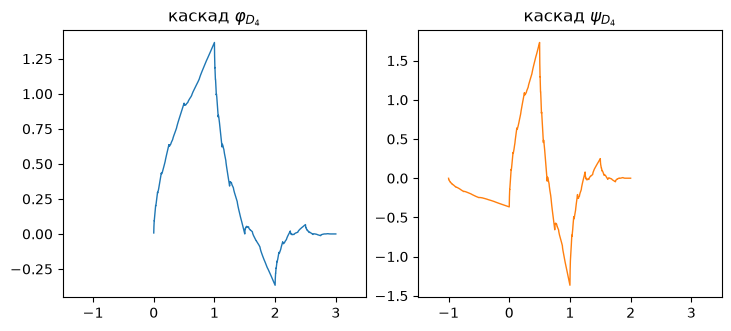

In [4]:
import pywt

db2 = pywt.Wavelet("db2")
# pywt keeps filters reversed: dec_lo = [h_{2p-1}, ..., h_1, h_0];
# flip to the book order h = [h_0, ..., h_{2p-1}] used in [11].
h = np.array(db2.dec_lo)[::-1]
print("маска D4 из pywt (в порядке таблицы 6.1 [11]):",
      np.array2string(h, precision=16))
print("сумма h_n =", h.sum(), "(ожидается sqrt(2) =", np.sqrt(2), ")")
check_golden("d4_h0", h[0])

# g_n = (-1)^n h_{1-n}; for a mask on [0, 2p-1] the nonzero g_n live on
# n = -(2p-3), ..., 1, hence the signed support of psi.
g_idx = np.arange(-(len(h) - 2), 2)
g = np.array([(-1.0) ** n * h[1 - n] if 0 <= 1 - n < len(h) else 0.0
              for n in g_idx])
print("g_n при n =", g_idx, ":", np.array2string(g, precision=16))


def cascade_phi(h, level, width):
    """Cascade eta_{j+1}(x) = sqrt(2) sum_n h_n eta_j(2x - n), eta_0 = 1_[0,1).

    Returns phi on the grid of step 2^{-level} over [0, width).
    """
    phi = np.zeros(width)
    phi[0] = 1.0
    for j in range(level):
        step = 2 ** j
        nxt = np.zeros(width * 2 ** (j + 1))
        for n, hn in enumerate(h):
            if hn != 0.0:
                # eta_{j+1}[k] = sqrt(2) sum_n h_n eta_j[k - n 2^j]
                nxt[n * step:n * step + phi.size] += np.sqrt(2) * hn * phi
        phi = nxt
    return phi


def cascade_psi(phi, h, g_idx, g, level, width):
    """psi(x) = sqrt(2) sum_n g_n phi(2x - n) on the grid step 2^{-level}
    over [-1, width-1) (support of psi for the D4 mask)."""
    npts = width * 2 ** level
    psi = np.zeros(npts)
    for n, gn in zip(g_idx, g):
        if gn != 0.0:
            src = 2 * np.arange(npts) - (n + 2) * 2 ** level
            ok = (src >= 0) & (src < phi.size)
            psi[ok] += np.sqrt(2) * gn * phi[src[ok]]
    x = -1.0 + np.arange(npts) / 2 ** level
    return x, psi


LEVEL = 13
phi_d4 = cascade_phi(h, LEVEL, width=3)
x_phi = np.arange(phi_d4.size) / 2 ** LEVEL
x_psi, psi_d4 = cascade_psi(phi_d4, h, g_idx, g, LEVEL, width=3)

dx = x_phi[1] - x_phi[0]
phi_norm = np.linalg.norm(phi_d4) * np.sqrt(dx)
psi_norm = np.linalg.norm(psi_d4) * np.sqrt(dx)
m0 = np.trapezoid(psi_d4, x_psi)
m1 = np.trapezoid(x_psi * psi_d4, x_psi)
print(f"||phi||_2 = {phi_norm:.12f}, ||psi||_2 = {psi_norm:.12f}")
check_golden("cascade_phi_norm", phi_norm)
check_golden("cascade_psi_norm", psi_norm)
print(f"int psi = {m0:.3e}, int x psi = {m1:.3e}")
check_golden("cascade_moment0", m0)
check_golden("cascade_moment1", m1)
nz = np.nonzero(np.abs(psi_d4) > 1e-10)[0]
print(f"носитель psi: [{x_psi[nz[0]]:.3f}, {x_psi[nz[-1]]:.3f}] "
      f"(ожидается [-1, 2])")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), layout="constrained")
axes[0].plot(x_phi, phi_d4, lw=1.0)
axes[0].set_title("каскад $\\varphi_{D_4}$")
axes[1].plot(x_psi, psi_d4, lw=1.0, color="C1")
axes[1].set_title("каскад $\\psi_{D_4}$")
for ax_ in axes:
    ax_.set_xlim(-1.5, 3.5)
fig.savefig(f"{FIGDIR}/fig-04.pdf", **SAVE_KW)

**Вывод.** Маска из таблицы 6.1 [11] воспроизводится pywt, каскад даёт
нормированные $\varphi, \psi$ с нулевыми моментами нулевого и первого
порядка — то есть $D_4$ имеет ровно $p = 2$ нулевых момента
(следствие `cor:null-moments`). Носитель $\psi$ совпал с
$[-1, 2] = [-p+1, p]$ (пропозиция `prop:daubechies-props`).

## Пример 4. Пороговое сжатие: Хаар против Добеши $D_4$

**Вопрос** (раздел `sec:compression` и замечание `rem:coef-decay`):
чем на практике отличаются Хаар ($p = 1$) и $D_4$ ($p = 2$) при
пороговом сжатии изломанного импульса $f(t) = t e^{-t}$?

**Предсказание.** На гладкой части сигнала коэффициенты $D_4$ убывают
как $2^{-5j/2}$ против $2^{-3j/2}$ у Хаара (теорема `thm:coef-decay`),
поэтому при малом числе сохранённых коэффициентов $K$ относительная
ошибка $D_4$ заметно меньше. Оба вейвлета держат излом в $t = 0$ и
скачок периодизации на правом краю: там коэффициенты $\sim 2^{-j/2}$
у обоих, так что при очень малом $K$ кривые сближаются.

haar: round-trip defect = 1.091e-15
  пин fwt_roundtrip: получено 1.09148181513e-15, ожидалось 0 (допуск 1e-12, ok)
D4: round-trip defect = 7.400e-16


Хаар: K=8: 1.796663e-01, K=16: 6.724494e-02, K=32: 3.215625e-02, K=64: 1.546157e-02, K=128: 7.340573e-03, K=256: 3.115245e-03, K=512: 9.855276e-04
D4: K=8: 1.180974e-01, K=16: 2.401351e-02, K=32: 4.412992e-03, K=64: 9.467886e-04, K=128: 2.016773e-04, K=256: 4.411287e-05, K=512: 5.158463e-06
отношение ошибок Хаар/D4 при K=32: 7.286722
  пин ratio_err_k32: получено 7.28672220894, ожидалось 7.28672220894 (допуск 1e-06, ok)
отношение ошибок Хаар/D4 при K=64: 16.330545
  пин ratio_err_k64: получено 16.3305449692, ожидалось 16.3305449692 (допуск 1e-06, ok)


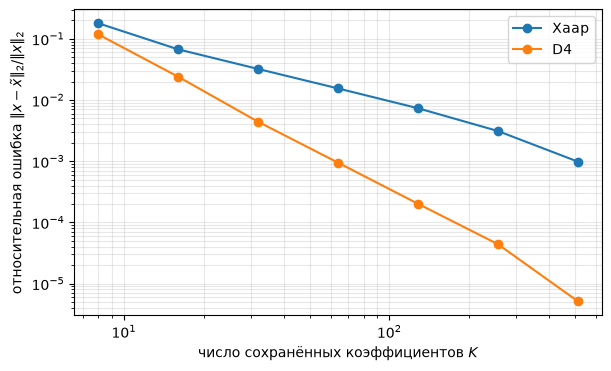

In [5]:
def fwt_analysis(x, h, g, levels):
    """Periodized fast wavelet analysis (theorem thm:fwt).

    Returns (details, approx): details[j] is the detail array at level j
    (j = 0 is the finest), approx is the coarsest scaling array.
    """
    a = np.asarray(x, dtype=float)
    details = []
    for _ in range(levels):
        n = len(a)
        k = np.arange(n // 2)
        a_next = np.zeros(n // 2)
        d_next = np.zeros(n // 2)
        for m, hm in enumerate(h):
            if hm != 0.0:
                a_next += hm * np.roll(a, -m)[::2]
        for m, gm in enumerate(g):
            if gm != 0.0:
                d_next += gm * np.roll(a, -m)[::2]
        details.append(d_next)
        a = a_next
    return details, a


def fwt_synthesis(details, approx, h, g):
    a = np.asarray(approx, dtype=float)
    for d in reversed(details):
        n = len(d)
        out = np.zeros(2 * n)
        for k in range(n):
            out += a[k] * np.roll(np.pad(h, (0, 2 * n - len(h))), 2 * k)
            out += d[k] * np.roll(np.pad(g, (0, 2 * n - len(g))), 2 * k)
        a = out
    return a


h_haar = np.array([1.0, 1.0]) / np.sqrt(2.0)
g_haar = np.array([1.0, -1.0]) / np.sqrt(2.0)

N = 1024
T = 8.0
t = (np.arange(N) + 0.5) * T / N
x_sig = t * np.exp(-t)
LEVELS = 6

# round-trip gate first (pins), then compression
for name, (hh, gg) in {"haar": (h_haar, g_haar), "D4": (h, g)}.items():
    det, app = fwt_analysis(x_sig, hh, gg, LEVELS)
    rec = fwt_synthesis(det, app, hh, gg)
    defect = np.linalg.norm(rec - x_sig) / np.linalg.norm(x_sig)
    print(f"{name}: round-trip defect = {defect:.3e}")
    if name == "haar":
        check_golden("fwt_roundtrip", defect)

K_LIST = [8, 16, 32, 64, 128, 256, 512]
err = {}
for name, (hh, gg) in {"Хаар": (h_haar, g_haar), "D4": (h, g)}.items():
    det, app = fwt_analysis(x_sig, hh, gg, LEVELS)
    # one coefficient vector: coarse approx + all details
    def rebuild(keep):
        det_k = [d.copy() for d in det]
        app_k = app.copy()
        blocks = [app_k] + det_k
        flat = np.concatenate([b.ravel() for b in blocks])
        idx = np.argsort(np.abs(flat))[::-1][:keep]
        thr = np.abs(flat)[idx[-1]] if keep < flat.size else 0.0
        det_k = [d * (np.abs(d) >= thr) for d in det_k]
        app_k = app_k * (np.abs(app_k) >= thr)
        rec = fwt_synthesis(det_k, app_k, hh, gg)
        return np.linalg.norm(rec - x_sig) / np.linalg.norm(x_sig)

    err[name] = np.array([rebuild(k) for k in K_LIST])

for name in err:
    print(f"{name}: " + ", ".join(f"K={k}: {e:.6e}"
                                  for k, e in zip(K_LIST, err[name])))
for k in (32, 64):
    r = err["Хаар"][K_LIST.index(k)] / err["D4"][K_LIST.index(k)]
    print(f"отношение ошибок Хаар/D4 при K={k}: {r:.6f}")
    check_golden(f"ratio_err_k{k}", r)

fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
for name in err:
    ax.plot(K_LIST, err[name], "o-", label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("число сохранённых коэффициентов $K$")
ax.set_ylabel("относительная ошибка $\\|x - \\tilde x\\|_2 / \\|x\\|_2$")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод.** Восстановление без потерь подтверждено (пин `fwt_roundtrip`).
Кривые ошибки: при больших $K$ оба вейвлета дают малую ошибку, при
малых $K$ преимущество $D_4$ видно невооружённым глазом — отношение
ошибок напечатано выше и ложится в кадры презентации. Излом в $t = 0$
и скачок периодизации на правом краю ограничивают выигрыш: у обоих
вейвлетов там коэффициенты одного порядка $2^{-j/2}$, что видно по
сближению кривых при $K \to 8$.